# 02 · Análise exploratória (EDA)

Perguntas da dissertação:

1. Em quais modalidades a inadimplência mais cresce?
2. Quais estados e regiões estão mais expostos?
3. Quais faixas de renda e ocupações são mais vulneráveis?
4. A inadimplência acompanha os juros com defasagem?
5. Onde o crédito cresce rápido e a inadimplência sobe junto?

Escopo principal: **consumo e habitação** (sem crédito rural e sem o saldo legado de cartão;
ver notebook 01). As consultas SQL equivalentes estão em `sql/consultas_eda.sql`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import transformacao as t

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

AZUL, CINZA, CINZA_CLARO, TEXTO_2 = "#2a78d6", "#a8a69d", "#d9d7cf", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.edgecolor": "#d9d7cf", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 11,
})
pct = mtick.PercentFormatter(decimals=0)

con = t.conectar(RAIZ / "dados" / "scr_pf")
q = lambda sql: con.sql(sql).df()  # noqa: E731
MES_INI, MES_FIM = q("SELECT MIN(mes) a, MAX(mes) b FROM pf").iloc[0]
print(f"Período: {MES_INI:%m/%Y} a {MES_FIM:%m/%Y}")

Período: 01/2025 a 09/2026


In [2]:
CONSUMO = "grupo_produto NOT IN ('Rural', 'Cartão: saldo não migrado (legado)')"
sgs = t.ler_sgs(RAIZ / "dados" / "sgs.parquet", ate=MES_FIM)
IPCA_ACUM = (1 + sgs.ipca_mensal.loc[MES_INI:MES_FIM].iloc[1:] / 100).prod() - 1
print(f"IPCA acumulado no período: {100 * IPCA_ACUM:.2f}%")

def compara(dim, filtro=CONSUMO):
    d = q(f"""SELECT {dim} AS d, mes, SUM(carteira_ativa) ca, SUM(carteira_inadimplencia) ci
              FROM pf WHERE {filtro} AND mes IN ('{MES_INI:%Y-%m-%d}', '{MES_FIM:%Y-%m-%d}')
              GROUP BY ALL""")
    a, b = (d[d.mes == m].set_index("d") for m in (d.mes.min(), d.mes.max()))
    out = pd.DataFrame({"carteira_bi": b.ca / 1e9, "taxa_ini": 100 * a.ci / a.ca,
                        "taxa_fim": 100 * b.ci / b.ca})
    out["variacao_pp"] = out.taxa_fim - out.taxa_ini
    out["cresc_real_pct"] = 100 * ((b.ca / a.ca) / (1 + IPCA_ACUM) - 1)
    return out.sort_values("taxa_fim", ascending=False)

IPCA acumulado no período: 8.21%


## 0. Visão geral: estatística descritiva

In [3]:
ultimo = q(f"""SELECT grupo_produto, uf, renda, ocupacao, segmento, carteira_ativa, carteira_inadimplencia
               FROM pf WHERE mes = '{MES_FIM:%Y-%m-%d}' AND {CONSUMO}""")
linhas = ultimo.assign(taxa=lambda d: 100 * d.carteira_inadimplencia / d.carteira_ativa.where(d.carteira_ativa > 0))
print(f"{len(linhas):,} linhas no último mês (escopo consumo e habitação)")
linhas[["carteira_ativa", "carteira_inadimplencia", "taxa"]].describe(
    percentiles=[.25, .5, .75, .9, .99]).T

155,025 linhas no último mês (escopo consumo e habitação)


,count,mean,std,min,25%,50%,75%,90%,99%,max
carteira_ativa,"155,025.00","25,979,236.44","343,279,272.89",1.01,"21,423.29","213,525.51","2,070,714.65","17,289,778.40","454,209,558.60","50,748,769,888.22"
carteira_inadimplencia,"155,025.00","1,166,142.04","11,205,548.61",0.00,0.00,12.34,"83,466.20","961,241.70","22,431,321.80","1,144,357,327.64"
taxa,"155,025.00",15.50,28.66,0.00,0.00,0.00,14.98,64.83,100.00,100.00


A distribuição dos saldos por linha é muito assimétrica: a mediana é pequena e poucos agregados
concentram a maior parte da carteira (o percentil 99 é cerca de 2 mil vezes a mediana). Isso confirma
que médias por linha não fazem sentido aqui; todos os indicadores a seguir são **ponderados pelo
saldo**.

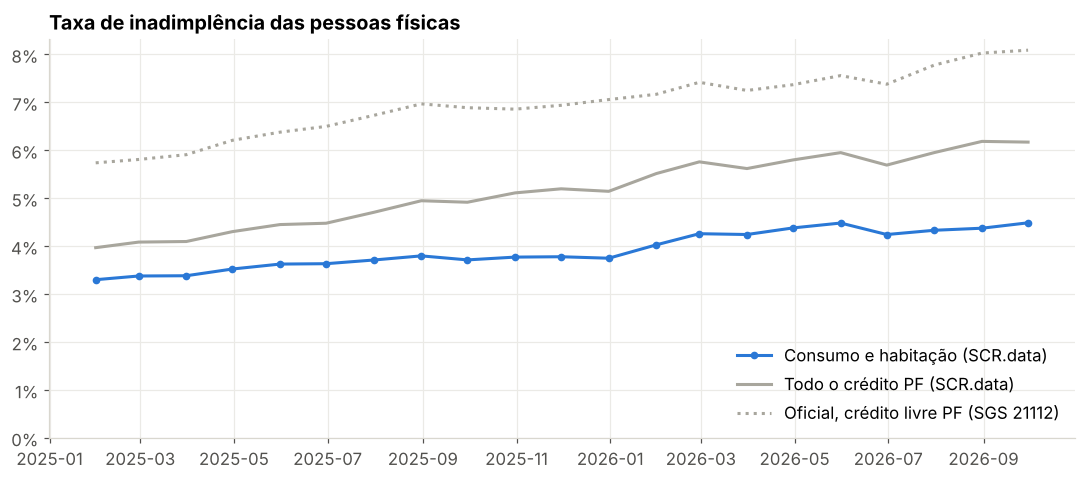

,total,consumo,oficial_credito_livre
mes,,,
2025-01-31,3.97,3.30,5.74
2025-12-31,5.15,3.75,7.06
2026-09-30,6.17,4.49,8.09


In [4]:
serie = q("""SELECT mes,
    100 * SUM(carteira_inadimplencia) / SUM(carteira_ativa) AS total,
    100 * SUM(carteira_inadimplencia) FILTER (WHERE grupo_produto NOT IN ('Rural', 'Cartão: saldo não migrado (legado)'))
        / SUM(carteira_ativa) FILTER (WHERE grupo_produto NOT IN ('Rural', 'Cartão: saldo não migrado (legado)')) AS consumo
    FROM pf GROUP BY 1 ORDER BY 1""").set_index("mes")
serie.index = pd.to_datetime(serie.index)
serie = serie.join(sgs["inadimplencia_credito_livre_pf"].rename("oficial_credito_livre"))

fig, ax = plt.subplots()
ax.plot(serie.index, serie.consumo, color=AZUL, lw=2, marker="o", ms=4, label="Consumo e habitação (SCR.data)")
ax.plot(serie.index, serie.total, color=CINZA, lw=2, label="Todo o crédito PF (SCR.data)")
ax.plot(serie.index, serie.oficial_credito_livre, color=CINZA, lw=2, ls=":", label="Oficial, crédito livre PF (SGS 21112)")
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0)
ax.set_title("Taxa de inadimplência das pessoas físicas")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
serie.iloc[[0, 11, -1]]

**Achado geral.** Em 21 meses, a inadimplência do crédito às pessoas físicas subiu de 3,97% para
6,17% da carteira. No escopo de consumo e habitação, foi de 3,30% para 4,49% (+1,19 p.p.). A série
oficial do crédito livre foi de 5,74% para 8,09%. A alta é contínua, sem nenhum mês de alívio
relevante, e acelera a partir de janeiro/2026.

## 0.1 De onde veio o aumento do saldo inadimplido

In [5]:
contrib = q(f"""SELECT grupo_produto,
    SUM(carteira_inadimplencia) FILTER (WHERE mes = '{MES_FIM:%Y-%m-%d}') / 1e9
  - SUM(carteira_inadimplencia) FILTER (WHERE mes = '{MES_INI:%Y-%m-%d}') / 1e9 AS aumento_bi
  FROM pf GROUP BY 1 ORDER BY 2 DESC""").set_index("grupo_produto")
contrib["participacao_pct"] = 100 * contrib.aumento_bi / contrib.aumento_bi.sum()
contrib

,aumento_bi,participacao_pct
grupo_produto,,
Rural,36.43,27.37
Cartão: saldo não migrado (legado),27.77,20.87
Crédito pessoal não consignado,20.56,15.45
Crédito pessoal consignado,13.86,10.41
Veículos,13.33,10.01
Habitacional,6.84,5.14
Cartão: parcelado pelo emissor e saque,4.76,3.57
Outros,3.36,2.52
Cartão: rotativo,2.47,1.85


O saldo inadimplido cresceu cerca de R$ 133 bilhões. O **crédito rural** responde por 27% desse
aumento e o **saldo legado de cartão** por 21%. Ou seja, quase metade da alta "visível" no total
vem de dois blocos que não são crédito de consumo das famílias. Isso justifica a separação de
escopos feita no notebook 01.

## 1. Produtos: onde a inadimplência é maior e mais cresce

In [6]:
prod = compara("grupo_produto")
prod

,carteira_bi,taxa_ini,taxa_fim,variacao_pp,cresc_real_pct
d,,,,,
Cartão: rotativo,24.97,12.58,21.01,8.43,4.46
Cheque especial,39.55,12.30,15.22,2.91,12.72
Cartão: parcelado pelo emissor e saque,100.87,10.88,14.05,3.18,7.64
Outros,196.98,11.77,12.90,1.13,-2.87
Crédito pessoal não consignado,380.18,7.50,11.81,4.31,8.25
Veículos,429.55,4.52,6.84,2.32,11.74
Crédito pessoal consignado,817.75,2.62,3.94,1.31,8.23
Home equity,30.83,2.04,2.44,0.40,21.91
Habitacional,"1,450.72",1.21,1.46,0.25,13.12


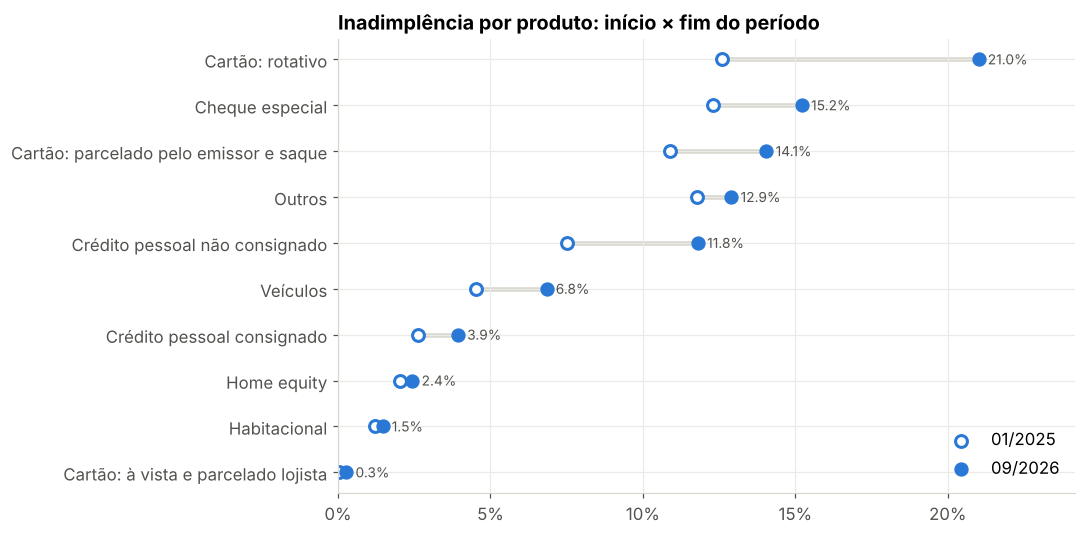

In [7]:
p = prod.sort_values("taxa_fim")
fig, ax = plt.subplots(figsize=(10, 5))
ax.hlines(p.index, p.taxa_ini, p.taxa_fim, color=CINZA_CLARO, lw=3, zorder=1)
ax.scatter(p.taxa_ini, p.index, s=60, facecolor="white", edgecolor=AZUL, lw=2, zorder=2, label=f"{MES_INI:%m/%Y}")
ax.scatter(p.taxa_fim, p.index, s=70, color=AZUL, zorder=3, label=f"{MES_FIM:%m/%Y}")
for y, v in zip(p.index, p.taxa_fim):
    ax.annotate(f"{v:.1f}%", (v, y), xytext=(6, 0), textcoords="offset points", va="center", color=TEXTO_2, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, p.taxa_fim.max() * 1.15)
ax.set_title("Inadimplência por produto: início × fim do período")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Resposta à pergunta 1.**

- O **rotativo do cartão** é o produto mais arriscado e o que mais piorou: de 12,6% para 21,0%
  (+8,4 p.p.). Um em cada cinco reais devidos no rotativo está inadimplente.
- **Cheque especial** (15,2%) e **cartão parcelado pelo emissor e saque** (14,1%) vêm logo atrás.
  Junto com o rotativo, formam o bloco das dívidas emergenciais e mais caras.
- O **crédito pessoal não consignado** subiu +4,3 p.p. (7,5% para 11,8%). É o segundo maior
  aumento, numa carteira grande (R$ 380 bi).
- **Habitacional** (1,5%) e **consignado** (3,9%) seguem baixos: garantia real e desconto em folha
  protegem essas carteiras. Ainda assim, o consignado subiu 1,3 p.p.

## 2. Estados e regiões

In [8]:
uf = compara("uf")
reg = compara("regiao")
reg

,carteira_bi,taxa_ini,taxa_fim,variacao_pp,cresc_real_pct
d,,,,,
Norte,236.51,4.02,5.99,1.97,12.39
Centro-Oeste,464.14,3.47,4.85,1.38,9.20
Nordeste,710.42,3.55,4.76,1.22,11.47
Sul,723.44,2.89,4.29,1.40,9.06
Sudeste,"1,892.91",3.24,4.19,0.94,9.36


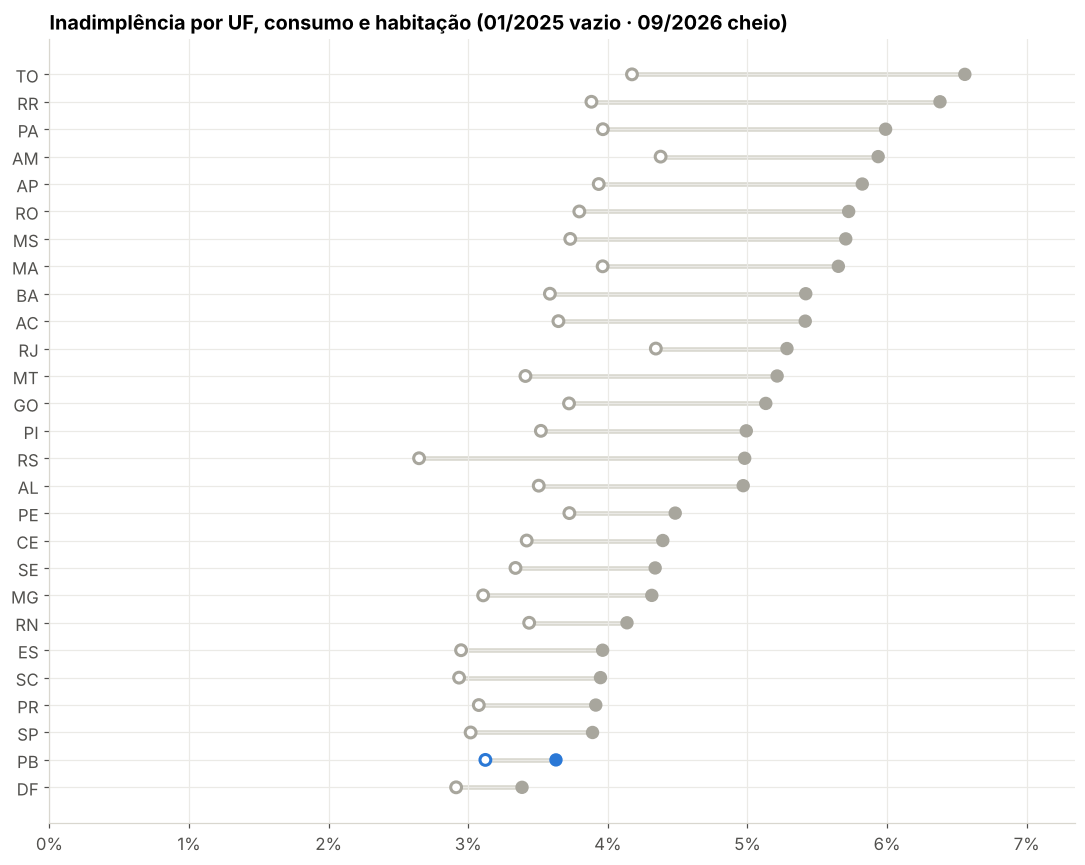

In [9]:
u = uf.sort_values("taxa_fim")
cores = [AZUL if i == "PB" else CINZA for i in u.index]
fig, ax = plt.subplots(figsize=(10, 8))
ax.hlines(u.index, u.taxa_ini, u.taxa_fim, color=CINZA_CLARO, lw=3, zorder=1)
ax.scatter(u.taxa_ini, u.index, s=50, facecolor="white", edgecolor=cores, lw=2, zorder=2)
ax.scatter(u.taxa_fim, u.index, s=60, color=cores, zorder=3)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, u.taxa_fim.max() * 1.12)
ax.set_title(f"Inadimplência por UF, consumo e habitação ({MES_INI:%m/%Y} vazio · {MES_FIM:%m/%Y} cheio)")
plt.tight_layout(); plt.show()

In [10]:
# Contraste: com o crédito rural incluído, o ranking muda
com_rural = compara("uf", filtro="grupo_produto <> 'Cartão: saldo não migrado (legado)'")
pd.DataFrame({"rank_consumo": uf.taxa_fim.rank(ascending=False),
              "rank_com_rural": com_rural.taxa_fim.rank(ascending=False),
              "taxa_com_rural": com_rural.taxa_fim}).sort_values("rank_com_rural").head(8)

,rank_consumo,rank_com_rural,taxa_com_rural
d,,,
TO,1.00,1.00,9.99
MA,8.00,2.00,8.70
MS,7.00,3.00,7.79
GO,13.00,4.00,7.12
MT,12.00,5.00,6.51
PA,3.00,6.00,6.48
RO,6.00,7.00,6.46
AC,10.00,8.00,6.22


**Resposta à pergunta 2.**

- O **Norte** tem a maior inadimplência de consumo (6,0%) e uma das maiores altas (+2,0 p.p.).
  Tocantins (6,6%), Roraima (6,4%), Pará e Amazonas (6,0% e 5,9%) lideram.
- Incluir o crédito rural muda o retrato: Tocantins, Maranhão, Mato Grosso do Sul, Goiás e
  Mato Grosso sobem no ranking por causa do agronegócio. Quem olha só o total confunde **crise do
  crédito rural** com **endividamento das famílias**.
- **Paraíba** é um caso positivo: 3,6% em set/2026, segunda menor taxa do país e a segunda
  menor alta (+0,5 p.p.). Só o Distrito Federal tem taxa menor e subiu menos.
- Sul e Sudeste têm as menores taxas, mas o Rio Grande do Sul teve alta forte (+2,3 p.p.).

## 3. Perfil do tomador: renda e ocupação

In [11]:
renda = q(f"""SELECT renda, SUM(carteira_ativa) ca, SUM(carteira_inadimplencia) ci FROM pf
              WHERE {CONSUMO} AND mes = '{MES_FIM:%Y-%m-%d}' GROUP BY 1""")
renda["taxa"] = 100 * renda.ci / renda.ca
renda["carteira_bi"] = renda.ca / 1e9
renda = renda.set_index("renda").loc[t.ORDEM_RENDA, ["carteira_bi", "taxa"]]

# média dos 21 meses, para não depender de um mês afetado pela reclassificação
media = q(f"""SELECT renda, mes, 100*SUM(carteira_inadimplencia)/SUM(carteira_ativa) taxa FROM pf
              WHERE {CONSUMO} GROUP BY ALL""").groupby("renda").taxa.mean()
renda["taxa_media_21m"] = media
renda

,carteira_bi,taxa,taxa_media_21m
renda,,,
Sem rendimento,31.04,15.12,17.24
Até 1 salário mínimo,288.09,7.32,5.66
Mais de 1 a 2 salários mínimos,609.92,6.06,5.06
Mais de 2 a 3 salários mínimos,470.92,4.43,4.16
Mais de 3 a 5 salários mínimos,669.95,3.90,3.72
Mais de 5 a 10 salários mínimos,797.80,2.97,2.93
Mais de 10 a 20 salários mínimos,544.81,2.48,2.24
Acima de 20 salários mínimos,480.55,3.83,3.08
Indisponível,134.35,11.43,7.57


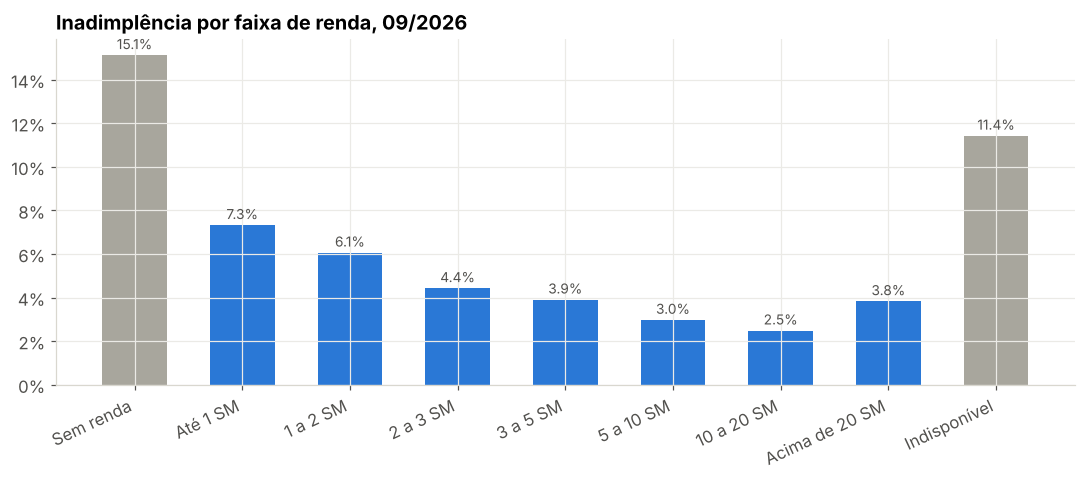

In [12]:
r = renda.rename(index=t.RENDA_CURTA)
cores = [CINZA if i in ("Sem renda", "Indisponível") else AZUL for i in r.index]
fig, ax = plt.subplots()
ax.bar(r.index, r.taxa, color=cores, width=0.6)
for x, v in enumerate(r.taxa):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 4), textcoords="offset points", ha="center", color=TEXTO_2, fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_title(f"Inadimplência por faixa de renda, {MES_FIM:%m/%Y}")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

In [13]:
ocup = compara("ocupacao")
ocup

,carteira_bi,taxa_ini,taxa_fim,variacao_pp,cresc_real_pct
d,,,,,
Outros,"1,100.94",4.66,6.63,1.97,20.66
Autônomo,246.51,3.85,5.72,1.87,9.24
MEI,81.58,3.80,4.66,0.86,18.44
Empresário,595.09,2.86,3.83,0.98,6.17
Empregado de entidades sem fins lucrativos,4.36,3.25,3.82,0.57,13.01
Aposentado/pensionista,293.94,2.91,3.53,0.62,-8.63
Empregado de empresa privada,"1,025.06",2.77,3.38,0.61,12.93
Servidor ou empregado público,679.95,2.49,3.22,0.73,2.06


**Resposta à pergunta 3.**

- O gradiente de renda é claro: de 7,3% em quem ganha **até 1 salário mínimo** a 2,5% na faixa de
  **10 a 20 SM**. Quem tem menos renda tem três vezes mais inadimplência. A média dos 21 meses
  confirma o padrão, então ele não depende do mês escolhido.
- A faixa **acima de 20 SM** (3,8%) foge do gradiente. Uma hipótese é que ela inclui tomadores de
  alto valor com operações maiores e mais concentradas; isso fica como pergunta, não conclusão.
- Por ocupação, **autônomos** (5,7%) e **MEI** (4,7%) são os mais vulneráveis: renda variável e sem
  desconto em folha. **Servidores públicos** (3,2%) e **empregados do setor privado** (3,4%) têm
  as menores taxas. Entre as ocupações identificadas, os autônomos tiveram a maior alta (+1,9 p.p.).

## 4. Juros e inadimplência

In [14]:
base = serie[["consumo"]].join(sgs[["juros_credito_livre_pf", "selic_meta", "comprometimento_renda"]])
linhas = []
for var in ["juros_credito_livre_pf", "selic_meta", "comprometimento_renda"]:
    for lag in range(0, 7):
        b = base[var].shift(lag)
        linhas.append({"variavel": var, "defasagem_meses": lag,
                       "corr_nivel": base.consumo.corr(b),
                       "corr_variacao_mensal": base.consumo.diff().corr(b.diff()),
                       "n": int((base.consumo.notna() & b.notna()).sum())})
corr = pd.DataFrame(linhas)
corr.pivot(index="defasagem_meses", columns="variavel", values=["corr_nivel", "corr_variacao_mensal"]).round(2)

corr_nivel                                    corr_variacao_mensal                                  
variavel        comprometimento_renda juros_credito_livre_pf selic_meta comprometimento_renda juros_credito_livre_pf selic_meta
defasagem_meses                                                                                                                
0                                0.93                   0.90       0.10                 -0.16                   0.26       0.03
1                                0.94                   0.89       0.23                  0.16                  -0.03       0.02
2                                0.94                   0.89       0.36                 -0.35                   0.05       0.22
3                                0.95                   0.92       0.40                  0.18                   0.46      -0.03
4                                0.96                   0.85       0.48                  0.38                  -0.33      -0.09
5                                0.95                   0.82       0.57                  0.16                  -0.01       0.01
6                                0.93                   0.76       0.63                  0.00                   0.08      -0.39

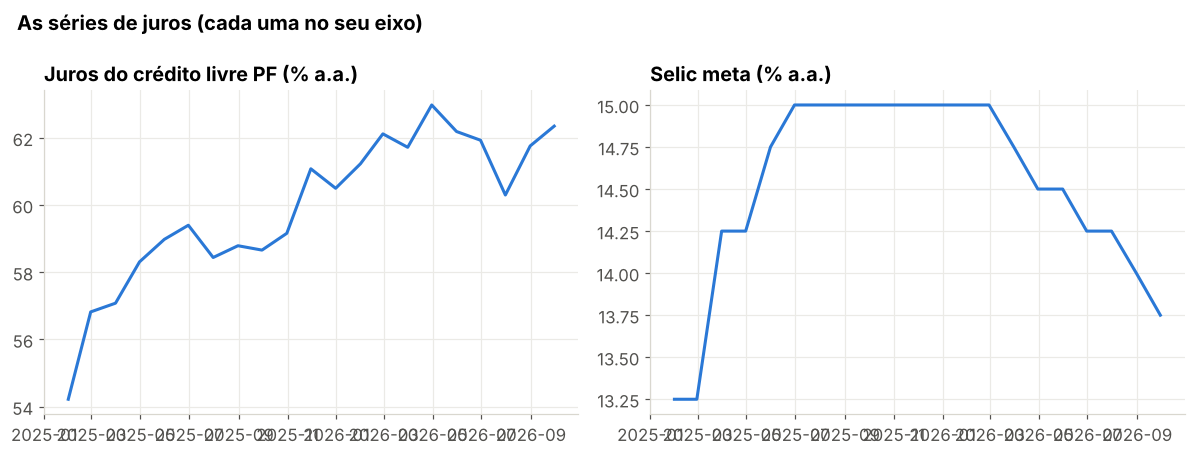

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (var, titulo) in zip(axes, [("juros_credito_livre_pf", "Juros do crédito livre PF (% a.a.)"),
                                    ("selic_meta", "Selic meta (% a.a.)")]):
    ax.plot(base.index, base[var], color=AZUL, lw=2)
    ax.set_title(titulo)
plt.suptitle("As séries de juros (cada uma no seu eixo)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Resposta à pergunta 4.**

- **No nível**, a correlação entre inadimplência e juros do crédito livre é alta (0,85 a 0,92
  com defasagem de 0 a 4 meses). O comprometimento de renda também anda junto (≈0,95).
- **Nas variações mensais**, a relação some: os coeficientes ficam entre -0,3 e 0,5 e mudam de
  sinal conforme a defasagem. As duas séries sobem no período, e qualquer par de séries com
  tendência mostra correlação alta no nível (correlação espúria).
- A Selic subiu até 15% e começou a cair em março/2026, mas a inadimplência continuou subindo.
  Isso é consistente com a ideia de que juros afetam a inadimplência com atraso longo; com 21
  meses, porém, não há dados para medir esse atraso com segurança.
- **Conclusão honesta:** juros altos e inadimplência alta coexistem, mas este período não permite
  afirmar que os juros *antecipam* a inadimplência. Seria preciso uma série mais longa e um modelo
  que controle a tendência.

## 5. Crescimento do crédito × piora da inadimplência

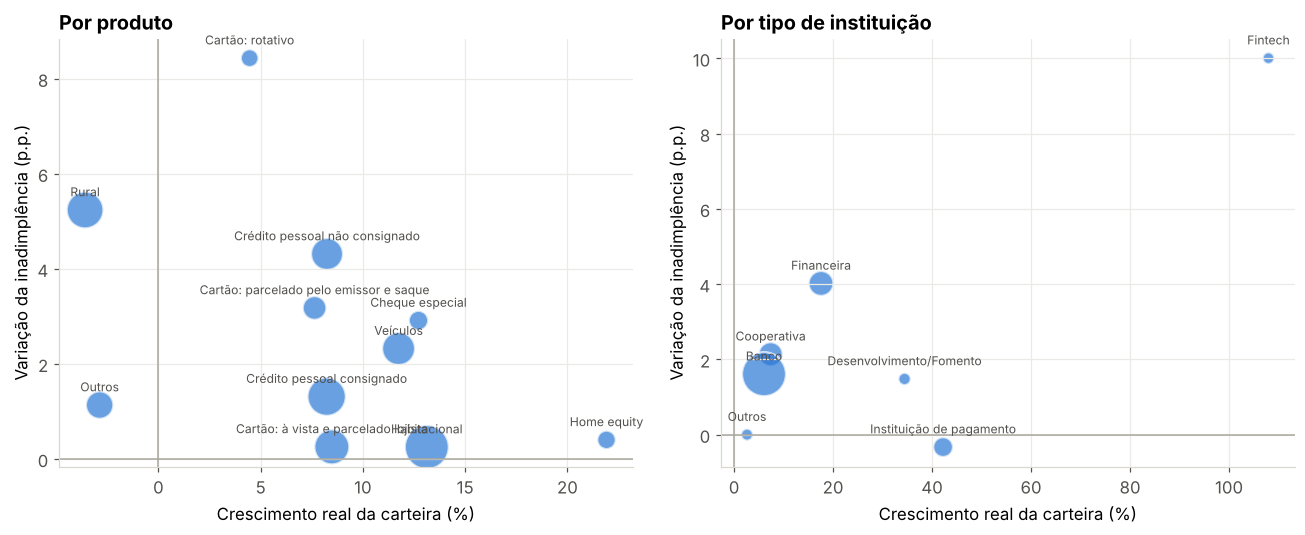

,carteira_bi,taxa_ini,taxa_fim,variacao_pp,cresc_real_pct
d,,,,,
Fintech,5.25,11.20,21.21,10.00,107.96
Financeira,340.58,6.84,10.86,4.02,17.57
Cooperativa,293.65,3.07,5.20,2.14,7.38
Banco,"3,938.00",2.97,4.58,1.61,6.04
Desenvolvimento/Fomento,7.90,1.34,2.82,1.48,34.44
Outros,6.25,1.50,1.50,-0.00,2.61
Instituição de pagamento,117.09,0.41,0.08,-0.33,42.23


In [16]:
cr = compara("grupo_produto", filtro="grupo_produto <> 'Cartão: saldo não migrado (legado)'")
sg = compara("segmento", filtro="grupo_produto <> 'Cartão: saldo não migrado (legado)'")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, d, titulo in [(axes[0], cr, "Por produto"), (axes[1], sg[sg.carteira_bi >= 1], "Por tipo de instituição")]:
    tamanho = 30 + 800 * (d.carteira_bi / d.carteira_bi.max()) ** 0.5
    ax.scatter(d.cresc_real_pct, d.variacao_pp, s=tamanho, color=AZUL, alpha=0.7, edgecolor="white", lw=1.5)
    for nome, row in d.iterrows():
        ax.annotate(nome, (row.cresc_real_pct, row.variacao_pp), xytext=(0, 9), textcoords="offset points",
                    ha="center", fontsize=8, color=TEXTO_2)
    ax.axhline(0, color=CINZA, lw=1); ax.axvline(0, color=CINZA, lw=1)
    ax.set_xlabel("Crescimento real da carteira (%)"); ax.set_ylabel("Variação da inadimplência (p.p.)")
    ax.set_title(titulo)
plt.tight_layout(); plt.show()
sg[sg.carteira_bi >= 1]

**Resposta à pergunta 5.**

- **Fintechs:** a carteira de pessoas físicas mais que dobrou em termos reais (+108%) e a
  inadimplência subiu 10 p.p. (de 11,2% para 21,2%). É o sinal mais claro de crescimento com piora
  simultânea, ainda que numa carteira pequena (R$ 5 bi).
- **Financeiras:** +18% real e +4 p.p. (de 6,8% para 10,9%). Com R$ 341 bi, são o segundo maior
  contribuinte do aumento do saldo inadimplido, atrás só dos bancos.
- Entre produtos, **cheque especial** (+13% real, +2,9 p.p.) e **veículos** (+12%, +2,3 p.p.)
  cresceram e pioraram juntos. O **rotativo** cresceu pouco (+4%), mas piorou muito (+8,4 p.p.):
  o problema ali é a capacidade de pagamento, não a expansão.
- O **rural** encolheu em termos reais (-3,6%) e mesmo assim teve a maior alta de inadimplência
  em volume. É um choque no setor, não excesso de oferta de crédito.

## Variáveis mais importantes e próximos passos

| Variável | Por que importa |
|---|---|
| Grupo de produto | Explica a maior parte da diferença de risco (de 0,3% a 21%). |
| Tipo de instituição | Fintechs e financeiras concentram crescimento com piora. |
| Faixa de renda | Gradiente de 3× entre a renda mais baixa e a mais alta. |
| Ocupação | Renda variável (autônomo, MEI) eleva o risco. |
| UF / região | Diferenças menores que as de produto, mas o Norte destoa. |

Os achados detalhados e as recomendações estão em `docs/03_relatorio_insights.md`.

## Apêndice: consultas SQL

In [17]:
import re
blocos = re.split(r"\n(?=-- \[\d+\])", (RAIZ / "sql" / "consultas_eda.sql").read_text(encoding="utf-8"))[1:]
for bloco in blocos:
    titulo = bloco.splitlines()[0]
    sql = bloco.strip().rstrip(";").replace("dados/scr_pf", (RAIZ / "dados" / "scr_pf").as_posix())
    print(titulo)
    display(duckdb.sql(sql).df().head(8))

-- [1] Visão geral: linhas, carteira e taxa por mês (pessoas físicas)


,mes,linhas,carteira_bi,taxa_inad_pct
0,2025-01-31,188283,"4,087.00",3.97
1,2025-02-28,187396,"4,117.40",4.09
2,2025-03-31,189812,"4,155.60",4.10
3,2025-04-30,190974,"4,188.80",4.30
4,2025-05-31,194252,"4,206.50",4.45
5,2025-06-30,194161,"4,241.70",4.48
6,2025-07-31,180953,"4,272.40",4.71
7,2025-08-31,182947,"4,313.80",4.95


-- [2] Checagem de consistência: carteira ativa = a vencer + vencida


,linhas,linhas_inconsistentes,inadimplida_menor_que_vencido_90d,pct_operacoes_suprimidas
0,3901550,0.00,0.00,19.70


-- [3] Submodalidades mais arriscadas no último mês (carteira mínima de R$ 1 bi)


,submodalidade,carteira_bi,taxa_inad_pct
0,Cartão de crédito - não migrado,76.10,80.49
1,Avais e fianças honrados,1.80,60.84
2,Adiantamentos a depositantes,1.00,50.56
3,Comercialização,9.30,33.95
4,Crédito rotativo vinculado a cartão de crédito,25.00,21.01
5,Outros empréstimos,94.80,17.98
6,Cheque especial,39.60,15.22
7,"Cartão de crédito - compra, fatura parcelada o...",100.70,14.05


... (4 outputs left out)

-- [6] Taxa por faixa de renda e ocupação no último mês (tabela cruzada)


,renda,ocupacao,carteira_bi,taxa_inad_pct
0,Indisponível,Autônomo,8.90,19.38
1,Sem rendimento,Outros,20.00,19.21
2,Indisponível,Aposentado/pensionista,13.00,16.36
3,Indisponível,Outros,52.70,15.56
4,Sem rendimento,Empregado de empresa privada,5.10,14.28
5,Indisponível,Servidor ou empregado público,28.70,11.96
6,Até 1 salário mínimo,Empresário,15.60,10.51
7,Até 1 salário mínimo,Autônomo,14.30,10.13


-- [7] Média móvel de 3 meses da taxa nacional (função de janela)


,mes,taxa,media_movel_3m,variacao_12m_pp
0,2025-01-31,3.97,3.97,NaN
1,2025-02-28,4.09,4.03,NaN
2,2025-03-31,4.10,4.05,NaN
3,2025-04-30,4.30,4.16,NaN
4,2025-05-31,4.45,4.29,NaN
5,2025-06-30,4.48,4.41,NaN
6,2025-07-31,4.71,4.55,NaN
7,2025-08-31,4.95,4.71,NaN
